In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
sales = pd.read_csv(Path.cwd().parent / "data/raw/sales_train_validation.csv")
cal = pd.read_csv(Path.cwd().parent / "data/raw/calendar.csv")
day_cols = [c for c in sales.columns if c.startswith("d_")]

# --- Ячейка 1: дневной ряд с настоящими датами. Агрегируем по строкам
# wide-формата (без melt!) — память почти не тратим.
d_to_date = cal.set_index("d")["date"]

def daily_series(store_id=None, dept_id=None, item_id=None):
    """Суммарные дневные продажи для среза: магазин / отдел / товар."""
    df = sales
    if store_id: df = df[df["store_id"] == store_id]
    if dept_id: df = df[df["dept_id"] == dept_id]
    if item_id: df = df[df["item_id"] == item_id]
    s = df[day_cols].sum()                                     # Series: d_1..d_1913
    s.index = pd.to_datetime(d_to_date.loc[day_cols].values)   # d_N -> дата
    s.index.name = "date"
    s.name = "units"
    return s

daily = daily_series(store_id="CA_3")         # наш лидер из задания d (task 01_data_overview)
print(daily.head(3), daily.mean().round(0))   # ~5 848 шт/день — сверь с расчётом

date
2011-01-29    4739
2011-01-30    4827
2011-01-31    3785
Name: units, dtype: int64 5848.0


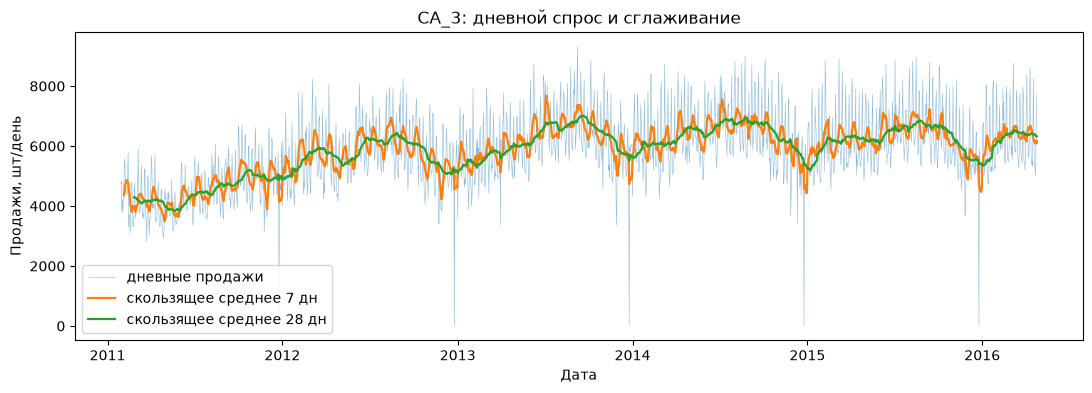

In [10]:
# --- Ячейка 2: тренд глазами — сырой ряд + скользящие средние
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily, lw=0.4, alpha=0.5, label="дневные продажи")
ax.plot(daily.rolling(7).mean(), lw=1.6, label="скользящее среднее 7 дн")
ax.plot(daily.rolling(28).mean(), lw=1.6, label="скользящее среднее 28 дн")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажи, шт/день")
ax.set_title("СА_3: дневной спрос и сглаживание")
ax.legend()
plt.show()

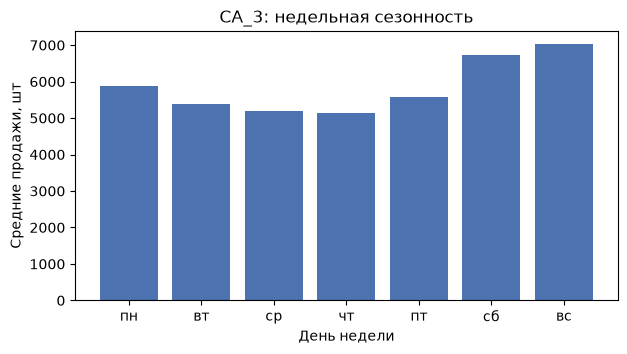

In [4]:
# --- Ячейка 3: недельная сезонность — средние по дням недели
by_wd = daily.groupby(daily.index.day_of_week).mean()   # 0 = понедельник
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(["пн", "вт", "ср", "чт", "пт", "сб", "вс"], by_wd.values, color="#4c72b0")
ax.set_xlabel("День недели")
ax.set_ylabel("Средние продажи, шт")
ax.set_title("CA_3: недельная сезонность")
plt.show()

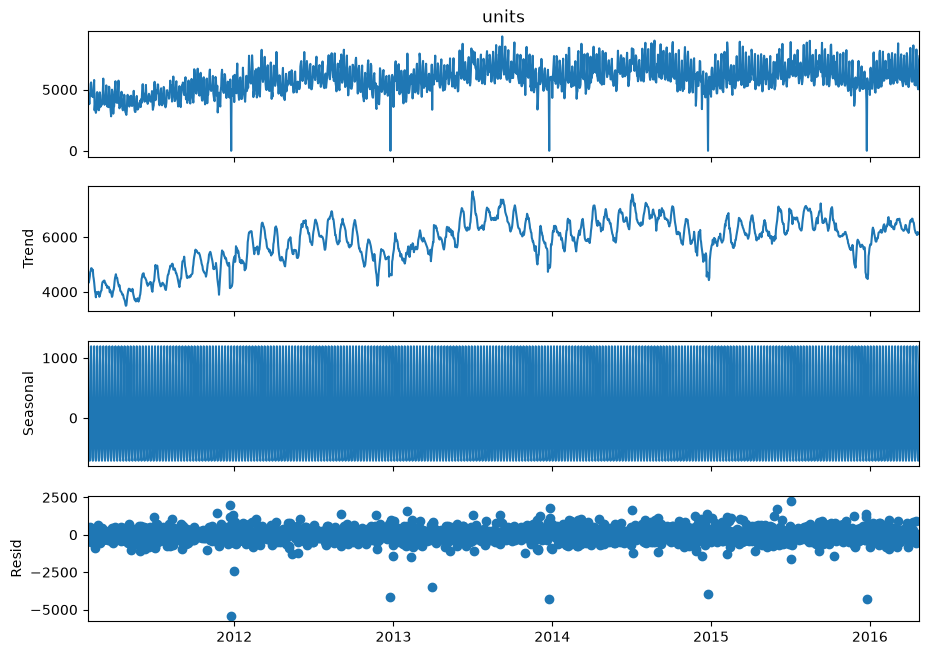

In [5]:
# --- Ячейка 4: декомпозиция (аддитивная, период 7 дней)
from statsmodels.tsa.seasonal import seasonal_decompose
dec = seasonal_decompose(daily, model="additive", period=7)
fig = dec.plot()
fig.set_size_inches(10, 7)   # подписи компонентов statsmodels ставит сам
plt.show()

In [8]:
# --- Ячейка 5: стационарность — тест Дики–Фуллера на исходном и на разностях
from statsmodels.tsa.stattools import adfuller
res = adfuller(daily, result_object=False)
print(f"Исходный ряд: ADF stat={res[0]:.2f}, p-value={res[1]:.5f}")
res_1 = adfuller(daily.diff().dropna(), result_object=False)
print(f"После diff(): ADF stat={res_1[0]:.2f}, p-value={res_1[1]:.5f}")

Исходный ряд: ADF stat=-2.40, p-value=0.14254
После diff(): ADF stat=-20.34, p-value=0.00000


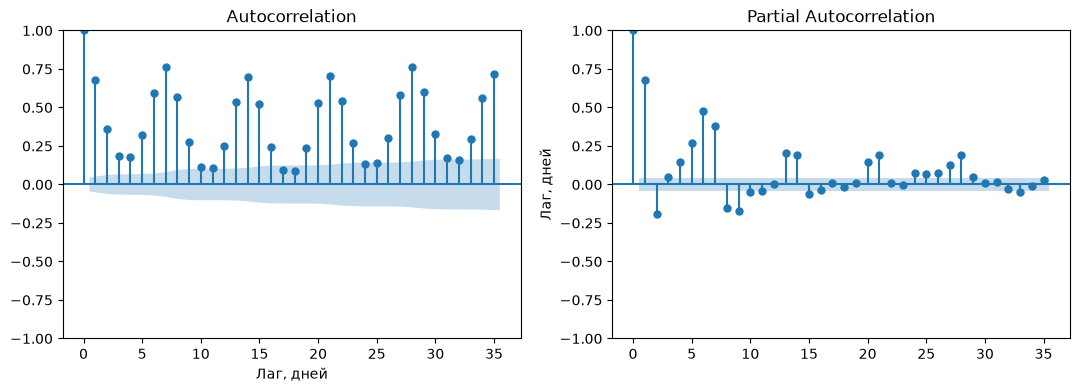

In [9]:
# --- Ячейка 6: ACF/PACF
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(daily, lags=35, ax=axes[0])
plot_pacf(daily, lags=35, ax=axes[1], method="ywm")
axes[0].set_xlabel("Лаг, дней")
axes[1].set_ylabel("Лаг, дней")
plt.show()

In [14]:
# 1. Проверка: есть ли нули/отрицательные в ряду
n_zero = (daily <= 0).sum()
print(f"Дней с нулевыми/отрицательными продажами: {n_zero}")
print(f"Минимальное значение: {daily.min()}")

# 2. Аддитивная декомпозиция — на всём ряду (нули не мешают)
dec = seasonal_decompose(daily, model="additive", period=7)
resid_add = dec.resid

# 3. Мультипликативная — только на положительных значениях
#    (мультипликативная модель требует Y = T × S × R, где R > 0)
daily_pos = daily[daily > 0]
dec_m = seasonal_decompose(daily_pos, model="multiplicative", period=7)

# 4. Приведение мультипликативных остатков к штукам
#    Мультипликативная модель: Y = T × S × R, где R ≈ 1
#    R - 1 = относительное отклонение (например, 0.05 = +5%)
#    (R - 1) × T = абсолютное отклонение в штуках
resid_mul = (dec_m.resid - 1) * dec_m.trend

# 5. Сравнение std — теперь обе метрики в штуках
print(f"std additive:      {resid_add.std():.0f} шт")
print(f"std multiplicative: {resid_mul.std():.0f} шт")

Дней с нулевыми/отрицательными продажами: 1
Минимальное значение: 0
std additive:      483 шт
std multiplicative: 546 шт
